# Filtering
This exercise is about understanding how filters can be applied to modify, or extract specific features from images.

<article class="message">
    <div class="message-body">
        <strong>List of individual tasks</strong>
        <ul style="list-style: none;">
            <li>
            <a href="#pixel_shift1">Task 1: Shifting pixels</a>
            </li>
            <li>
            <a href="#gaussian">Task 2: Gaussian blurring</a>
            </li>
            <li>
            <a href="#template_match">Task 3: Template matching</a>
            </li>
            <li>
            <a href="#sharp">Task 4: Sharpening</a>
            </li>
            <li>
            <a href="#gradient_features0">Task 5: Apply sobel filters</a>
            </li>
            <li>
            <a href="#gradient_features">Task 6: Implementing convolution</a>
            </li>
        </ul>
    </div>
</article>

Run the following cell to import the libraries:


In [6]:
import numpy as np
from skimage import data, color
from scipy.ndimage import convolve
from skimage import feature, transform, io
import matplotlib.pyplot as plt

The same set of example images from the Scikit-Image library used in the tutorial will be used. The code below can be used or modified to load and inspect any of the images.


['astronaut', 'binary_blobs', 'brain', 'brick', 'camera', 'cat', 'cell', 'cells3d', 'checkerboard', 'chelsea', 'clock', 'coffee', 'coins', 'colorwheel', 'data_dir', 'download_all', 'eagle', 'file_hash', 'grass', 'gravel', 'horse', 'hubble_deep_field', 'human_mitosis', 'immunohistochemistry', 'kidney', 'lbp_frontal_face_cascade_filename', 'lfw_subset', 'lily', 'logo', 'microaneurysms', 'moon', 'nickel_solidification', 'page', 'palisades_of_vogt', 'protein_transport', 'retina', 'rocket', 'shepp_logan_phantom', 'skin', 'stereo_motorcycle', 'text', 'vortex']


(np.float64(-0.5), np.float64(383.5), np.float64(302.5), np.float64(-0.5))

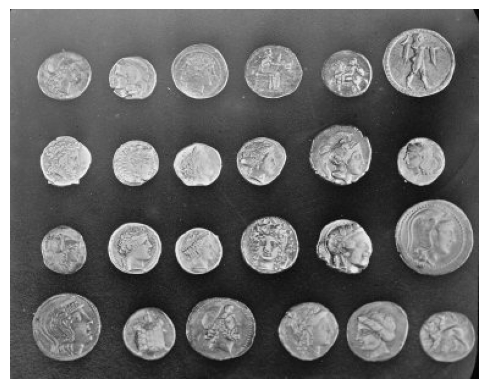

In [7]:
print(data.__all__)
plt.imshow(data.coins(), cmap="gray")
plt.axis(False)


---
**Task 1 (easy): Shifting pixels👩‍💻♾️**
This exercise is about understanding the fundamentals of linear filters to shift pixels in a certain direction. The actual filter may have little practical relevance. 
1. Construct a filter that shifts pixels of an image by $n$ pixels to the right. Create a function with parameter `n`
 that returns a filter that shifts the pixels of an image by `n`
 pixels to the right.
2. Apply the filter (convolution) to one of the example images and show the results. Experiment with different values for `n`
.
3. Create the functions `shift_to_left`
, `shift_to_up`
, and `shift_to_down`
 to shift the input images $n$ pixels to the left, up and down. Use one of the example images to test these functions and evaluate whether the images are correctly shifted. 
4. Modify the filter to not only shift the pixel to the right (or the other directions) but also decreases its brightness.


---

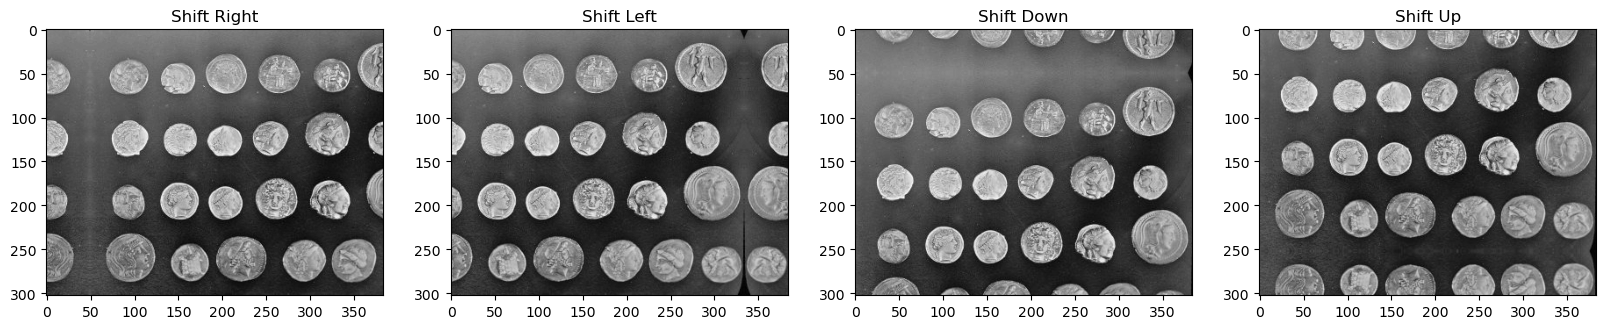

In [8]:
from click import BadArgumentUsage
import numpy as np
from scipy.ndimage import convolve
import matplotlib.pyplot as plt
from skimage import data

def shift_to_right(n, brightness_scale=0.4):
    """
    Shifts an image to the right by n pixels.
    And scales down the brightness 
    """
    # Kernel with scaling factor placed n columns from the left (shifting right).
    kernel = np.zeros((1, n+1))
    kernel[0, -1] = brightness_scale  # Place brightning factor at the far right of the kernel
    return kernel

def shift_to_left(n, brightness_scale=0.4):
    """
    Shifts an image to the left by n pixels.
    And scales down the brightness
    """
    # Kernel with scaling factor placed n columns from the right (shifting left).
    kernel = np.zeros((1, n+1))
    kernel[0, 0] = brightness_scale  # Place scaling factor at the far left of the kernel
    return kernel

def shift_to_down(n, brightness_scale=1):
    """
    Shifts an image down by n pixels.
    And scales down the brightness
    """
    # Kernel with scaling factor placed n rows from the top (shifting down).
    kernel = np.zeros((n+1, 1))
    kernel[-1, 0] = brightness_scale  # Place scaling factor at the bottom of the kernel
    return kernel

def shift_to_up(n, brightness_scale=1):
    """
    Shifts an image up by n pixels.
    And scales down the brightness
    """
    # Kernel with scaling factor placed n rows from the bottom (shifting up).
    kernel = np.zeros((n+1, 1))
    kernel[0, 0] = brightness_scale  # Place scaling factor at the top of the kernel
    return kernel

# Applying the shift to the image
image = data.coins()  
shifted_image_right = convolve(image, shift_to_right(100))
shifted_image_left = convolve(image, shift_to_left(100))
shifted_image_down = convolve(image, shift_to_down(100))
shifted_image_up = convolve(image, shift_to_up(100))

# Plotting the results
fig, ax = plt.subplots(1, 4, figsize=(20, 5))
ax[0].imshow(shifted_image_right, cmap='gray')
ax[0].set_title('Shift Right')
ax[1].imshow(shifted_image_left, cmap='gray')
ax[1].set_title('Shift Left')
ax[2].imshow(shifted_image_down, cmap='gray')
ax[2].set_title('Shift Down')
ax[3].imshow(shifted_image_up, cmap='gray')
ax[3].set_title('Shift Up')
plt.show()



---
**Task 2 (medium): Gaussian blurring👩‍💻**
The following steps will construct a Gaussian filter and apply it to an image:
1. Design a 3x3 filter for Gaussian blurring. Each element of the filter should be filled with values that approximate a Gaussian function.


**Hint**
The filter was covered during the lecture.

2. Display the Gaussian Blur filter using the cell below.
3. Apply the filter to one of the example images and display the original and blurred images side by side.
4. Explain the underlying reasons for the observed effects produced by this filter.
5. Increase the size of the Gaussian blurring filter (shown below). Apply the filter to the selected image and compare the results to the results obtained in the previous steps. Explain the observed effects. 


$$
\begin{equation}
\frac{1}{256}
\begin{bmatrix}
1 & 4 & 6 & 4 & 1 \\
4 & 16 & 24 & 16 & 4 \\
6 & 24 & 36 & 24 & 6 \\
4 & 16 & 24 & 16 & 4 \\
1 & 4 & 6 & 4 & 1 \\
\end{bmatrix}
\end{equation}
$$

---

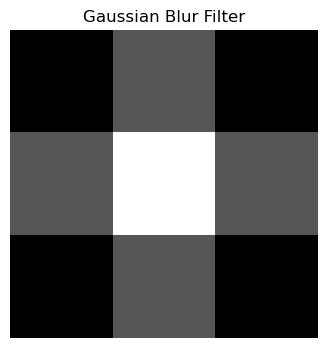

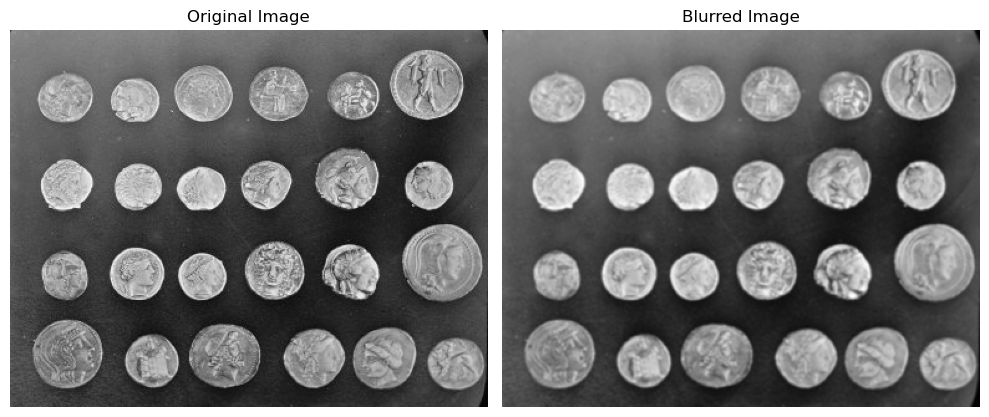

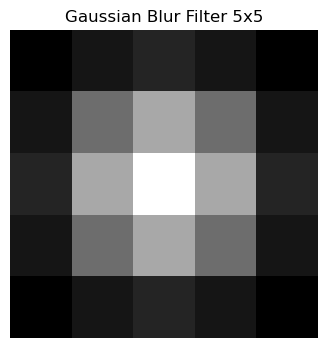

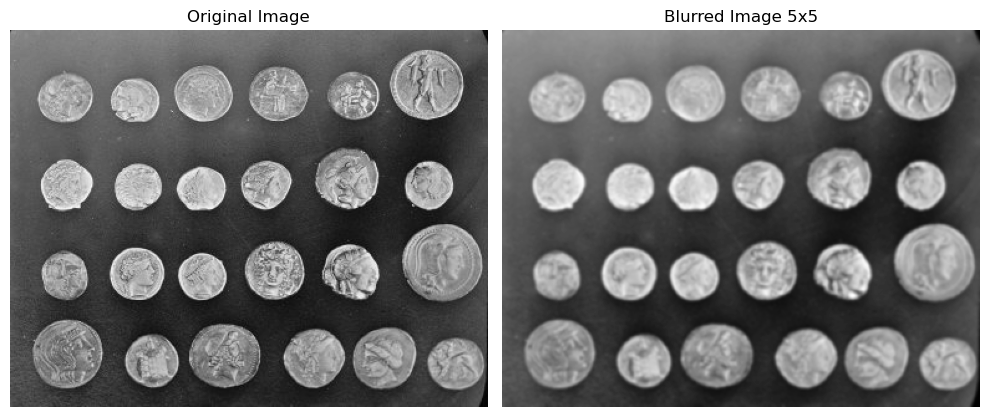

In [9]:
# write your solution here
gaussian_blur_filter = np.array([[1, 2, 1],
                                 [2, 4, 2],
                                 [1, 2, 1]]) / 16 # normalizing the filter so the sum of all elements is 1

# Plot the Gaussian Blur Filter
plt.figure(figsize=(4, 4))
plt.title('Gaussian Blur Filter')
plt.imshow(gaussian_blur_filter, cmap='gray')
plt.axis('off')
plt.show()

# Plot the original and the blurred image
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title('Original Image')
plt.imshow(image, cmap='gray')
plt.axis('off')

# Apply the Gaussian Blur Filter to the image
blurred_image = convolve(image, gaussian_blur_filter)

plt.subplot(1, 2, 2)
plt.title('Blurred Image')
plt.imshow(blurred_image, cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.show()



# Increase size of Gaussian filter to 5x5
gaussian_blur_filter_5x5 = np.array([[1, 4, 6, 4, 1],
                                     [4, 16, 24, 16, 4],
                                     [6, 24, 36, 24, 6],
                                     [4, 16, 24, 16, 4],
                                     [1, 4, 6, 4, 1]]) / 256 # normalizing the filter so the sum of all elements is 1

# Plot the Gaussian Blur Filter
plt.figure(figsize=(4, 4))
plt.title('Gaussian Blur Filter 5x5')
plt.imshow(gaussian_blur_filter_5x5, cmap='gray')
plt.axis('off')
plt.show()

# Plot the original and the blurred image
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title('Original Image')
plt.imshow(image, cmap='gray')
plt.axis('off')

# Apply the Gaussian Blur Filter to the image
blurred_image_5x5 = convolve(image, gaussian_blur_filter_5x5)

plt.subplot(1, 2, 2)
plt.title('Blurred Image 5x5')
plt.imshow(blurred_image_5x5, cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.show()
 
                                     



---
**Task 3 (medium): Template matching👩‍💻**
The following exercise is about implementing template matching on the sunflower image (`sunflowers.jpg`
) found in the data library for this week's exercises.
1. Run the cell below to load the image, convert it to grayscale and normalize its pixel values. 
2. Define a rectangular region of interest (ROI) within the image. This ROI will serve as the template you want to extract from the image and it should include the flower head of a single sunflower. Extract the template and display it.
3. Implement template matching by using the [`skimage.feature.match_template`
](https://scikit-image.org/docs/stable/auto_examples/features_detection/plot_template.html)
 function. The function returns a two-dimensional array (correlation map) that indicate the similarity or correlation between the template and regions of the input image. Display the results.
4. Was the template correctly matched to the original image? Were there any other areas that appeared to be potential matches?
5. (Optional) Repeat the steps above using convolution. What differences and similarities do you observe and why? Does it change if you normalize the filters or the image (or both) prior to convolution?


---

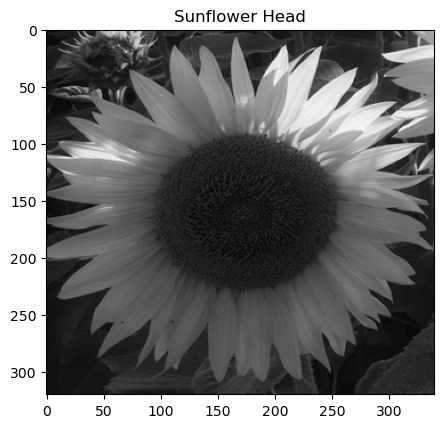

In [ ]:
img = io.imread("data/sunflowers.jpg")
img = color.rgb2gray(img).astype(np.float32)/255.

# Define a rectangular region of intrerest (ROI) in the image
# Should include the flower head of a single sunflower
roi = img[720:1040, 100:440]
# Display the template
plt.figure(figsize=(5, 5))
plt.title('Sunflower Head')
plt.imshow(roi, cmap='gray')
plt.show()

# Implement template matching using skimage.feature.match_template
# This function returns a 2D array with the similarity scores at each pixel location

# The maximum value in this array corresponds to the location of the template in the image
result = feature.match_template(img, roi)
# Display the result of template matching
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title('Sunflower Image')
plt.imshow(img, cmap='gray')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.title('Matching Result')
plt.imshow(result, cmap='gray')
plt.axis('off')
plt.show()


# Repeat using convolution
# The convolution operation is equivalent to template matching
# with the template flipped both horizontally and vertically
from scipy.signal import convolve2d

# Flip the template for convolution
template_flipped = np.flipud(np.fliplr(roi))

# Convolve the image with the flipped template
conv_result = convolve2d(img, template_flipped, mode='same')

# Display the result of template matching
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title('Sunflower Image')
plt.imshow(img, cmap='gray')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.title('Matching Result')
plt.imshow(conv_result, cmap='gray')
plt.axis('off')
plt.show()




---
**Task 4 (medium): Sharpening👩‍💻💡**
This task is about creating filters to sharpen the pixels of an input image, making details look clearer than in the original image. The following filters can be used for image sharpening:

$$
K_1=\frac{1}{9}\left[
	\begin{array}{r r r}
		-1 & -1 & -1 \\
		-1 & 17 & -1 \\
		-1 & -1 & -1
	\end{array}
\right],
K_2=\left[
	\begin{array}{r r r}
		-1 & -1 & -1 \\
		-1 &  9 & -1 \\
		-1 & -1 & -1
	\end{array}
\right]
$$
Notice that in this case the filter values sum to one.
1. Why do sharpen filters contain a single positive value at their centers, which are completely surrounded by negative values? Explain why the filters $K_1$ and $K_2$ lead to sharpening.	

2. Define the above filters as Numpy arrays.

3. Use the filters $K_1$ and $K_2$ to sharpen one of the example images from the Scikit-Image library. Show the two filtered images and compare them with the original input image.

4. Implement the sharpening filter shown below and apply it to the selected image. Reflect on the effects of increasing the size of the sharpening filter. 



$$
\frac{1}{8}
\begin{bmatrix}
-1 & -1 & -1 & -1 & -1 \\
-1 & 2 & 2 & 2 & -1 \\
-1 & 2 & 8 & 2 & -1 \\
-1 & 2 & 2 & 2 & -1 \\
-1 & -1 & -1 & -1 & -1 \\
\end{bmatrix}
$$

---

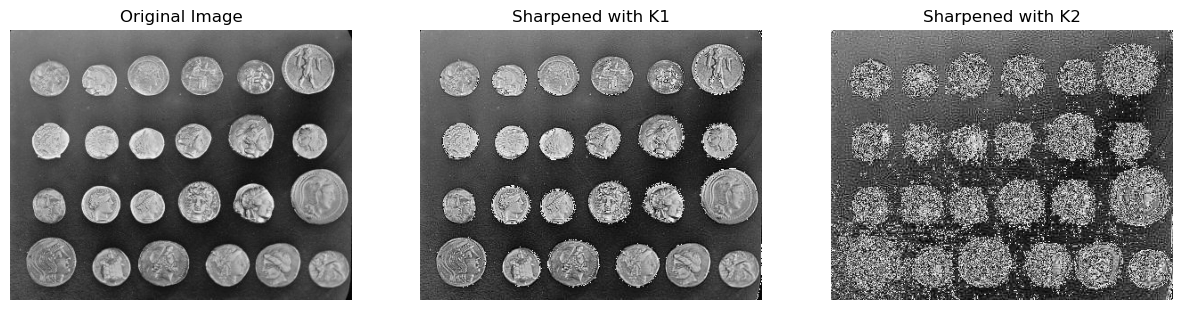

(np.float64(-0.5), np.float64(383.5), np.float64(302.5), np.float64(-0.5))

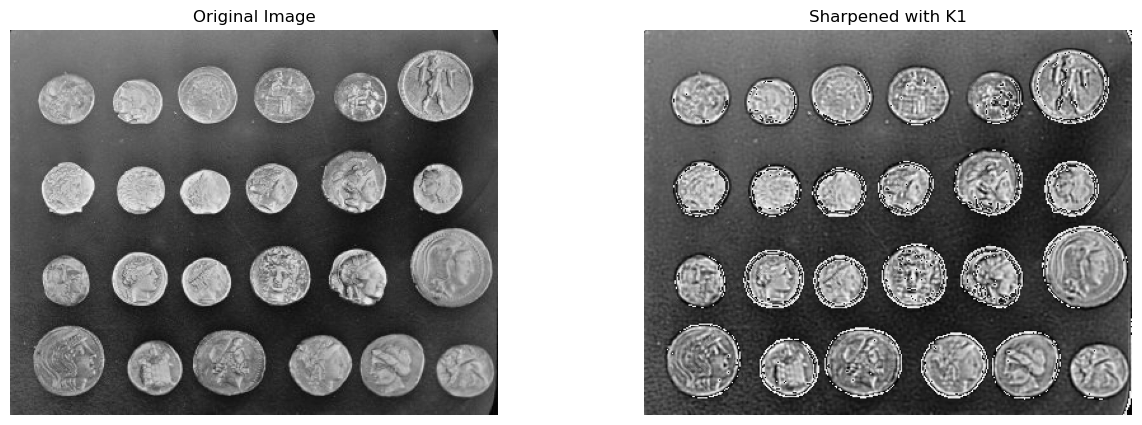

In [9]:
# write your solution here
"""
Sharpening filters are designed to enhance the edges within an image by emphasizing the differences between adjacent pixel values. 
The central positive value in the filter helps in retaining the intensity of the current pixel, while the surrounding negative values reduce the contribution of neighboring pixels. This contrast enhancement makes edges and details appear more defined.
"""

# Define sharpening filter K1
K1 = np.array([
    [-1, -1, -1],
    [-1, 17, -1],
    [-1, -1, -1]
]) / 9  # Normalizing by dividing by the sum of weights

# Define sharpening filter K2
K2 = np.array([
    [-1, -1, -1],
    [-1, 9, -1],
    [-1, -1, -1]
]) 

# Use the filters k1 and k2 to sharpen an image
sharpened_image_k1 = convolve(image, K1)
sharpened_image_k2 = convolve(image, K2)

from scipy.ndimage import convolve
import matplotlib.pyplot as plt

# Load an example image
image = (data.coins())

# Apply the K1 and K2 filters
sharpened_image_K1 = convolve(image, K1)
sharpened_image_K2 = convolve(image, K2)

# Plot the results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(image, cmap='gray')
axes[0].set_title('Original Image')
axes[0].axis('off')

axes[1].imshow(sharpened_image_K1, cmap='gray')
axes[1].set_title('Sharpened with K1')
axes[1].axis('off')

axes[2].imshow(sharpened_image_K2, cmap='gray')
axes[2].set_title('Sharpened with K2')
axes[2].axis('off')

plt.show()



# A larger filter
K3 = np.array([[ -1, -1, -1, -1, -1],
              [ -1,  2,  2,  2, -1],
              [ -1,  2,  8,  2, -1],
              [ -1,  2,  2,  2, -1],
              [ -1, -1, -1, -1, -1]]) / 8

# Apply to image
sharpened_image_K3 = convolve(image, K3)

# Plot the results
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].imshow(image, cmap='gray')
axes[0].set_title('Original Image')
axes[0].axis('off')

axes[1].imshow(sharpened_image_K3, cmap='gray')
axes[1].set_title('Sharpened with K1')
axes[1].axis('off')




---
**Task 5 (medium): Apply sobel filters👩‍💻**
The goal in this task is to construct derivative (sobel) filters in the x and y direction, and apply them to the image by using convolution.
The following steps must be completed: 
1. Constuct the two gradient filters defined by the matrices below:


$$
sobel_x=\left[
	\begin{array}{r r r}
		-1 & 0 & 1 \\
		-2 & 0 & 2 \\
		-1 & 0 & 1
	\end{array}
\right],
sobel_y=\left[
	\begin{array}{r r r}
		-1 & -2 & -1 \\
		0 &  0 & 0 \\
		1 & 2 & 1
	\end{array}
\right]
$$
2. Apply the sobel filters using  `convolve`
 from scipy on the sample image. Run the cell below to display the results.


---

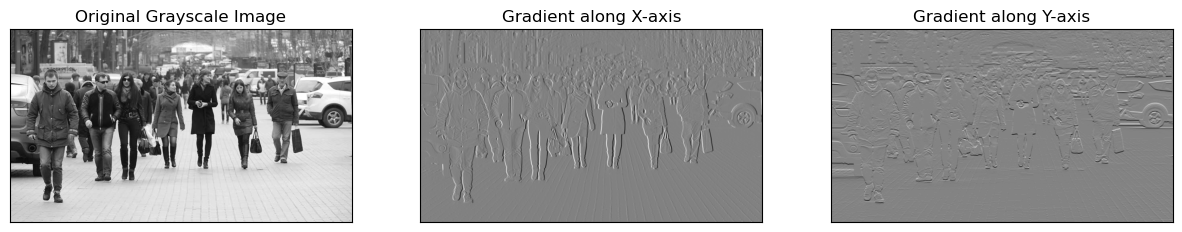

In [11]:
fn =  "./data/people01.jpg"
image = plt.imread(fn)

def rgb2gray(rgb):
    """Convert RGB image to grayscale
       Parameters:
        rgb : RGB image
       Returns:
        Grayscale image
    """
    return np.dot(rgb[...,:3], [0.2989, 0.5870, 0.1140])


# Convert the image to grayscale
gray_image = rgb2gray(image)

# Compute the gradients using the Sobel operator
# Define the Sobel operator kernels.

# Step 1: construct sobel filters 
sobelx = np.array([[-1, 0, 1],
                   [-2, 0, 2],
                   [-1, 0, 1]])
sobely = np.array([[-1, -2, -1],
                   [ 0,  0,  0],
                   [ 1,  2,  1]])

# Step 2: convolve the image with the filters
image_gradient_x = convolve(gray_image, sobelx)
image_gradient_y = convolve(gray_image, sobely)

# Step 3:  Visualize the original image and gradients with the following subplot template

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(gray_image, cmap='gray'),
plt.title('Original Grayscale Image')
plt.xticks([]), plt.yticks([])  # Hides the tick values on X and Y axis

plt.subplot(1, 3, 2)
plt.imshow(image_gradient_x, cmap='gray')
plt.title('Gradient along X-axis')
plt.xticks([]), plt.yticks([])  # Hides the tick values on X and Y axis

plt.subplot(1, 3, 3)
plt.imshow(image_gradient_y, cmap='gray')
plt.title('Gradient along Y-axis')
plt.xticks([]), plt.yticks([])  # Hides the tick values on X and Y axis
plt.show()


---
**Task 6 (medium): Implementing convolution👩‍💻**
1. For the previous exercise the `convolve`
 method from scipy was used to apply the filters. This task is about implementing convolution. Below is a breakdown of the `convolve2d`
 function used for performing a 2D convolution operation on an image:
    - Reverse the filter, flipping it both vertically and horizontally, to adhere to the convolution's mathematical definition.

    - Output preparation, create an empty array, the same size as the image, to capture the convolution results.

    - Add zero-padding around the image borders to ensure that the kernel properly processes the edges.

    - Convolution process, iterate over each pixel. For each, apply the kernel, multiply its values with the image segment, and sum the results to assign a new value to the pixel.





---

In [13]:
def convolve2d(image, kernel):
    """Perform 2D convolution on an image using a given kernel
       Parameters:
        image : 2D array
        kernel : 2D kernel array
       Returns:
        Convolved 2D array
    """
    # Reverse the kernel, flip it both horizontally and vertically
    kernel = np.flipud(np.fliplr(kernel))
    
    # Create an empty array with the same shape as the input image
    output = np.zeros_like(image)
    
    # Add zero padding around the edges of the image
    image_padded = np.zeros((image.shape[0] + 2, image.shape[1] + 2))
    image_padded[1:-1, 1:-1] = image
    
    # Perform 2D convolution
    # Iterate over each pixel, apply the kernel, multiply and sum the values
    for x in range(image.shape[1]):
        for y in range(image.shape[0]):
            output[y, x] = (kernel * image_padded[y: y+3, x: x+3]).sum()
    
    return output